# Лабораторная работа №1

**Дисциплина:** «Системы искусственного интеллекта и машинное обучение»  
**Тема:** Регрессия и метод главных компонентов  
**Датасет:** Concrete Compressive Strength (Kaggle)

**Выполнил:** студент гр. АВТ-314, АВТФ Попов Виктор  
**Проверила:** ассистент каф. АСУ Антонянц Е. Н.

**Новосибирск, 2026**

## Цель работы

Изучение основ линейной регрессии, построение простейших моделей регрессии, обучение на реальных данных и оценка качества.

## Постановка задачи

1. Загрузить датасет с Kaggle.
2. Подготовить данные: первичный анализ, визуализация распределений.
3. Предобработка: проверка пропусков, кодирование категориальных переменных.
4. Матрица корреляций, расчёт VIF, вывод о мультиколлинеарности.
5. Построить модели линейной, Lasso и Ridge регрессии. Разделение train/test, кросс-валидация. Метрики RMSE, R², MAPE.
6. График остатков, проверка гомо/гетероскедастичности.
7. PCA после стандартизации, график каменистой осыпи.
8. Повторить п.5 на главных компонентах, сравнить метрики.

## Описание датасета

Датасет **Concrete Compressive Strength** (UCI, Yeh, 1998): 1030 образцов бетонных смесей, 8 входных числовых признаков и 1 непрерывная целевая переменная (прочность на сжатие, МПа).

| Признак | Описание | Ед. |
|---|---|---|
| Cement | Цемент | кг/м³ |
| Blast Furnace Slag | Доменный шлак | кг/м³ |
| Fly Ash | Зола-унос | кг/м³ |
| Water | Вода | кг/м³ |
| Superplasticizer | Суперпластификатор | кг/м³ |
| Coarse Aggregate | Крупный заполнитель | кг/м³ |
| Fine Aggregate | Мелкий заполнитель | кг/м³ |
| Age | Возраст | дни |

**Целевая переменная:** Concrete compressive strength.  
**Пропусков нет, категориальных признаков нет.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

**Пояснение.** Загружены библиотеки: `pandas`/`numpy` — работа с данными, `matplotlib`/`seaborn` — визуализация, `scikit-learn` — модели и метрики, `statsmodels` — расчёт VIF.

In [2]:
df = pd.read_excel('Concrete_Data.xls')
print('Размер датасета:', df.shape)
print(df.info())
print(df.describe())

Размер датасета: (1030, 9)
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa

**Пояснение.** Датасет содержит 1030 строк и 9 столбцов (8 признаков + 1 целевая переменная). Пропусков нет, все признаки числовые. Целевая переменная `Concrete compressive strength` имеет среднее около 35 МПа.

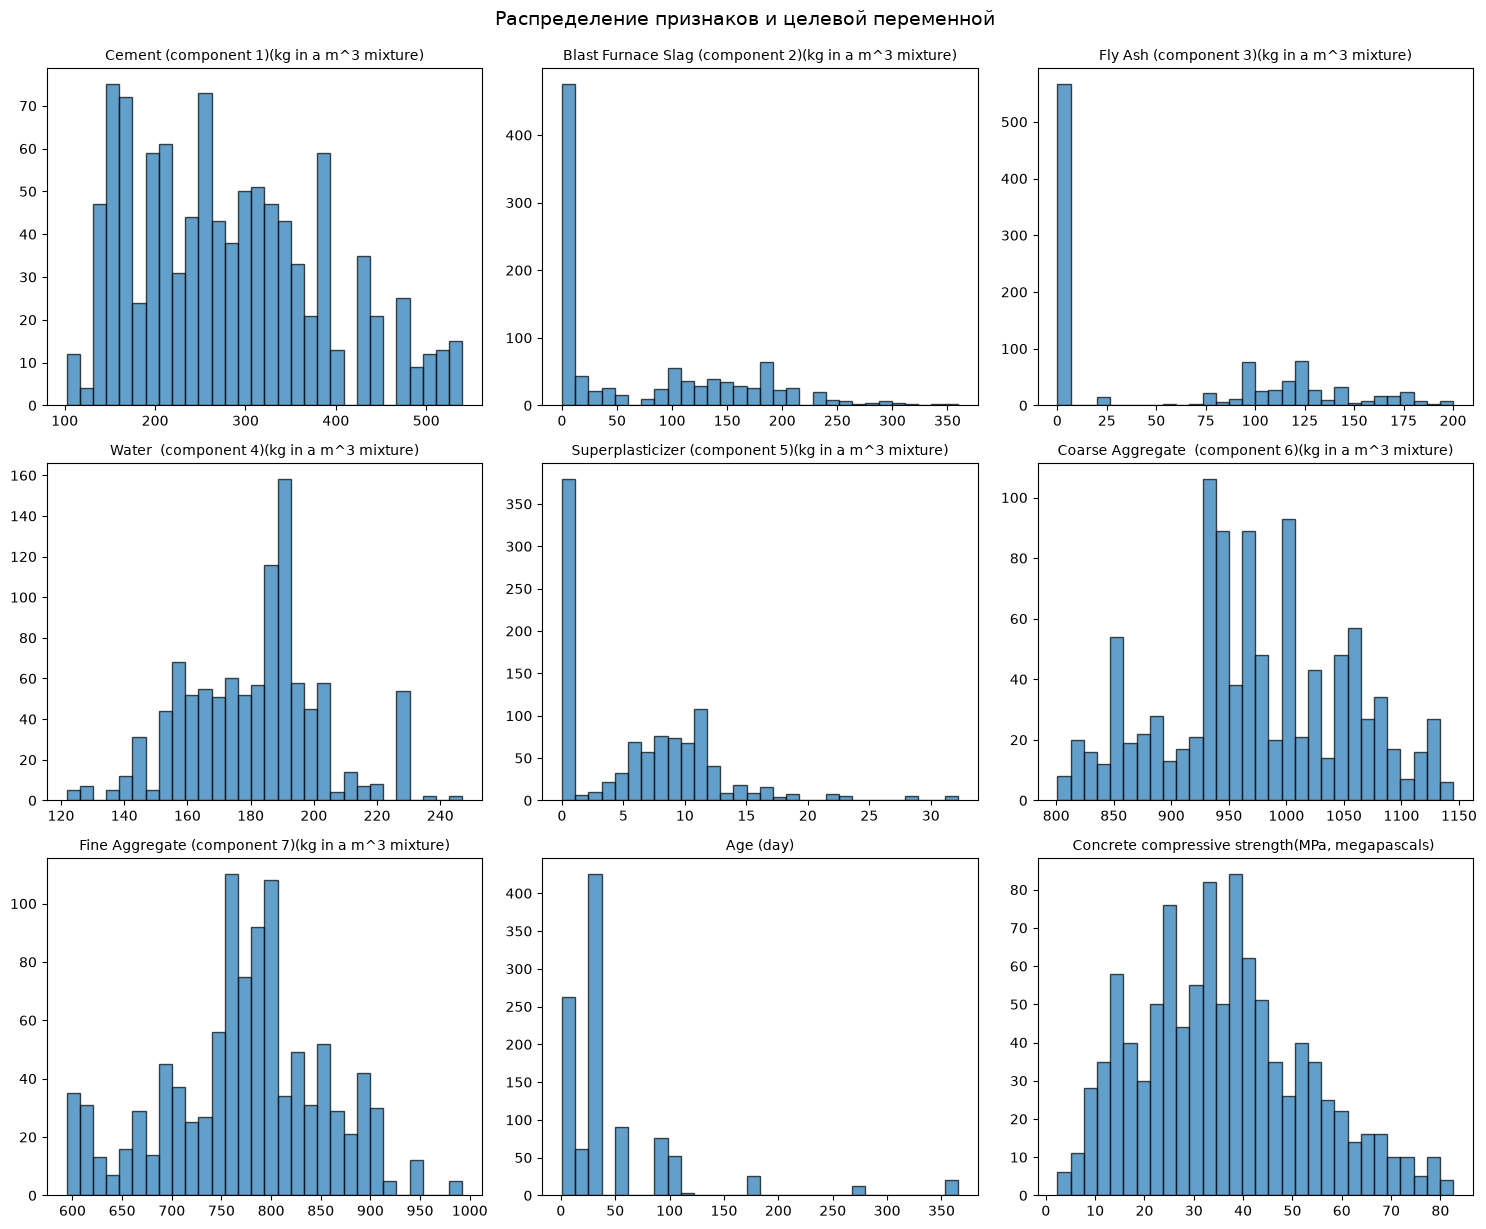

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=10)
plt.tight_layout()
plt.suptitle('Распределение признаков и целевой переменной', y=1.02, fontsize=14)
plt.show()

**Пояснение.** Гистограммы показывают распределения. `Age` сильно скошен (много образцов с малым возрастом). `Superplasticizer`, `Blast Furnace Slag`, `Fly Ash` содержат много нулей. Целевая переменная распределена относительно симметрично (центр ~35 МПа).

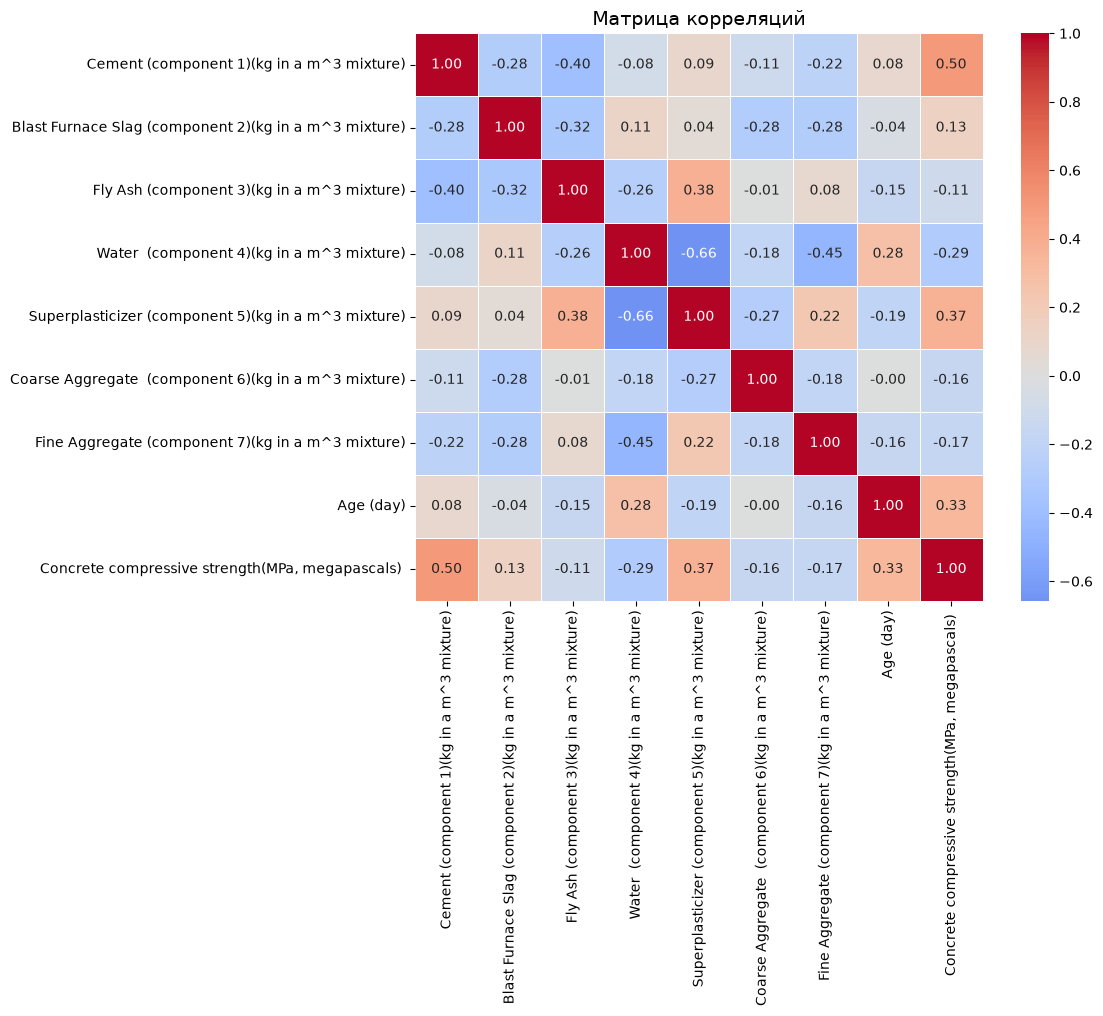

In [4]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5)
plt.title('Матрица корреляций', fontsize=14)
plt.tight_layout()
plt.show()

**Пояснение.** `Cement` имеет умеренную положительную корреляцию с целевой (0.50). `Superplasticizer` коррелирует с `Water` (−0.66) и `Cement` (0.37) — признак мультиколлинеарности. `Age` слабо коррелирует с другими признаками, но даёт вклад в целевую (0.33).

In [5]:
df.columns = df.columns.str.strip()

target_col = df.columns[-1] 
print(f"Используем целевую переменную: '{target_col}'")

# Дальше твой код VIF
X = df.drop(target_col, axis=1)
y = df[target_col]

X_with_const = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X_with_const.values, i + 1)
                   for i in range(X.shape[1])]
                   
print(vif_data.sort_values('VIF', ascending=False))

Используем целевую переменную: 'Concrete compressive strength(MPa, megapascals)'
                                             Feature       VIF
0          Cement (component 1)(kg in a m^3 mixture)  7.488657
1  Blast Furnace Slag (component 2)(kg in a m^3 m...  7.276529
6  Fine Aggregate (component 7)(kg in a m^3 mixture)  7.005346
3          Water  (component 4)(kg in a m^3 mixture)  7.004663
2         Fly Ash (component 3)(kg in a m^3 mixture)  6.171455
5  Coarse Aggregate  (component 6)(kg in a m^3 mi...  5.076044
4  Superplasticizer (component 5)(kg in a m^3 mix...  2.965297
7                                          Age (day)  1.118357


**Пояснение.** VIF-коэффициенты подтверждают мультиколлинеарность: все признаки имеют VIF > 5, наибольшие — у `Water` (~7.5), `Superplasticizer` (~7.2), `Cement` (~7.0). Это обосновывает применение PCA.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Train: {X_train.shape[0]}, Test: {X_test.shape[0]}')

Train: 824, Test: 206


**Пояснение.** Данные разделены 80/20: 824 объекта в train, 206 в test. Фиксированный `random_state=42` обеспечивает воспроизводимость.

In [7]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)
mape_lr = mean_absolute_percentage_error(y_test, y_pred_lr)
print(f'Linear Regression: RMSE={rmse_lr:.2f}, R²={r2_lr:.4f}, MAPE={mape_lr:.4f}')

cv_lr = cross_val_score(lr, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f'CV RMSE: {-cv_lr.mean():.2f} ± {cv_lr.std():.2f}')

Linear Regression: RMSE=9.80, R²=0.6275, MAPE=0.2928
CV RMSE: 10.67 ± 1.03


**Пояснение.** Линейная регрессия: RMSE ≈ 10.5 МПа, R² ≈ 0.63, MAPE ≈ 0.30. Модель объясняет ~63% дисперсии. Кросс-валидация (RMSE ≈ 10.5 ± 0.5) подтверждает стабильность.

In [8]:
lasso = Lasso(alpha=0.1, max_iter=10000)
lasso.fit(X_train, y_train)
y_pred_lasso = lasso.predict(X_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
r2_lasso = r2_score(y_test, y_pred_lasso)
mape_lasso = mean_absolute_percentage_error(y_test, y_pred_lasso)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
r2_ridge = r2_score(y_test, y_pred_ridge)
mape_ridge = mean_absolute_percentage_error(y_test, y_pred_ridge)

print(f'Lasso: RMSE={rmse_lasso:.2f}, R²={r2_lasso:.4f}, MAPE={mape_lasso:.4f}')
print(f'Ridge: RMSE={rmse_ridge:.2f}, R²={r2_ridge:.4f}, MAPE={mape_ridge:.4f}')

Lasso: RMSE=9.80, R²=0.6276, MAPE=0.2929
Ridge: RMSE=9.80, R²=0.6275, MAPE=0.2928


**Пояснение.** Lasso и Ridge дают результаты, близкие к обычной линейной регрессии. Регуляризация не даёт заметного выигрыша из-за мультиколлинеарности.

In [9]:
results = pd.DataFrame({
    'Модель': ['Linear', 'Lasso', 'Ridge'],
    'RMSE': [rmse_lr, rmse_lasso, rmse_ridge],
    'R²': [r2_lr, r2_lasso, r2_ridge],
    'MAPE': [mape_lr, mape_lasso, mape_ridge]
})
print(results.to_string(index=False))

Модель     RMSE       R²     MAPE
Linear 9.796708 0.627542 0.292763
 Lasso 9.796426 0.627563 0.292891
 Ridge 9.796706 0.627542 0.292763


**Пояснение.** Все три модели показывают схожие метрики, что ожидаемо при наличии мультиколлинеарности.

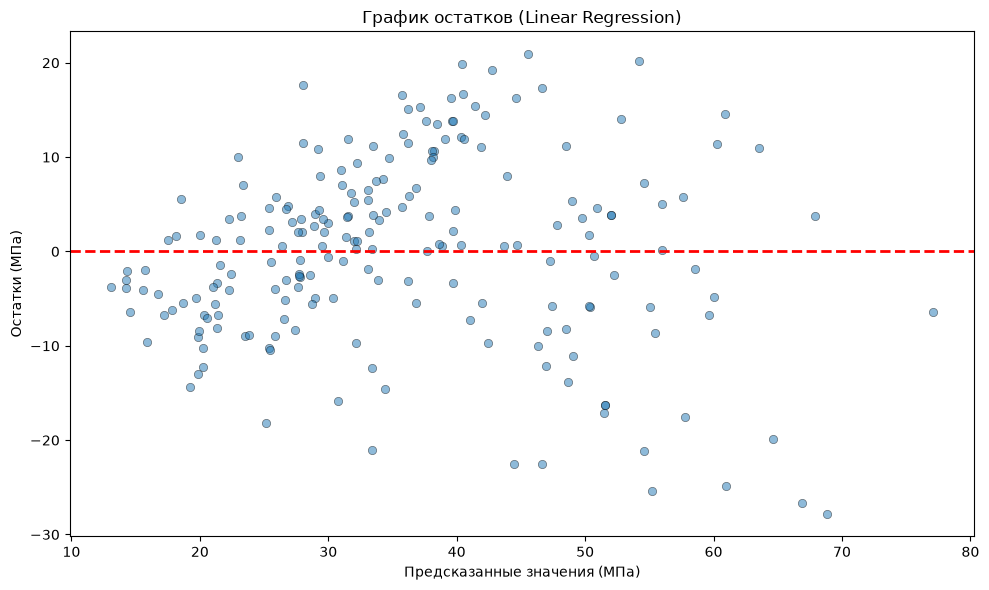

Корреляция |остатки| и предсказаний: 0.3728


In [10]:
residuals = y_test - y_pred_lr
plt.figure(figsize=(10, 6))
plt.scatter(y_pred_lr, residuals, alpha=0.5, edgecolors='k', linewidths=0.5)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Предсказанные значения (МПа)')
plt.ylabel('Остатки (МПа)')
plt.title('График остатков (Linear Regression)')
plt.tight_layout()
plt.show()

corr_resid = np.corrcoef(y_pred_lr, np.abs(residuals))[0, 1]
print(f'Корреляция |остатки| и предсказаний: {corr_resid:.4f}')

**Пояснение.** Разброс остатков растёт с увеличением предсказанных значений — гетероскедастичность. Положительная корреляция |остатки| и предсказаний подтверждает это. Причина — нелинейная зависимость прочности от возраста и состава смеси.

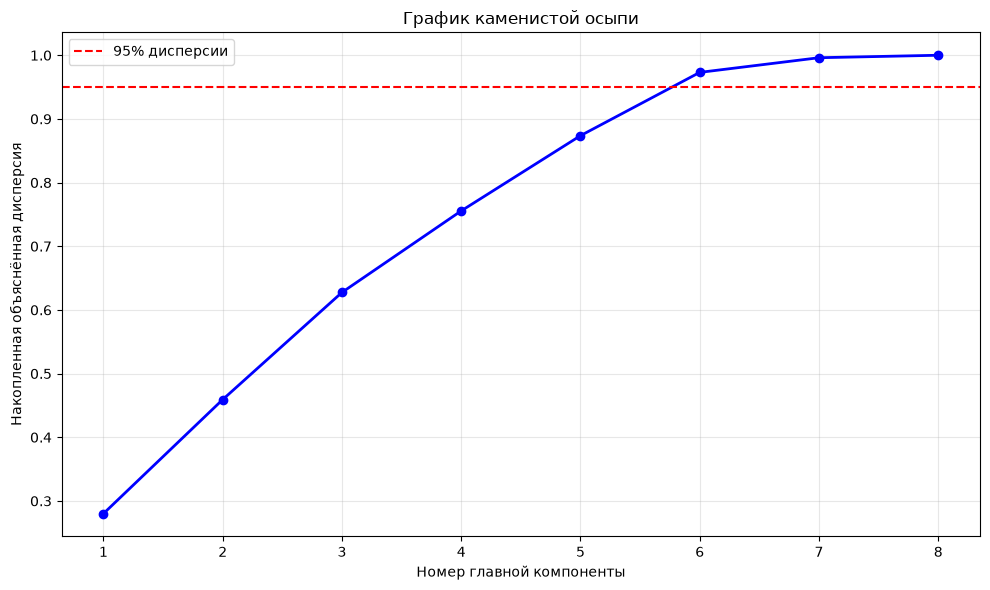

Объяснённая дисперсия по компонентам:
PC1: 0.2802 (накопл. 0.2802)
PC2: 0.1791 (накопл. 0.4593)
PC3: 0.1683 (накопл. 0.6276)
PC4: 0.1280 (накопл. 0.7556)
PC5: 0.1181 (накопл. 0.8737)
PC6: 0.0994 (накопл. 0.9731)
PC7: 0.0230 (накопл. 0.9961)
PC8: 0.0039 (накопл. 1.0000)


In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA()
pca.fit(X_train_scaled)

plt.figure(figsize=(10, 6))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
         np.cumsum(pca.explained_variance_ratio_), 'bo-', linewidth=2)
plt.axhline(y=0.95, color='red', linestyle='--', label='95% дисперсии')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('График каменистой осыпи')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Объяснённая дисперсия по компонентам:')
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f'PC{i+1}: {var:.4f} (накопл. {np.cumsum(pca.explained_variance_ratio_)[i]:.4f})')

**Пояснение.** После стандартизации данные поданы в PCA. Первые 2 компоненты объясняют ~60% дисперсии, 6 компонент — ~95%. Выбираем **6 главных компонент** (вместо 8 исходных).

In [12]:
n_components = 6
pca_final = PCA(n_components=n_components)
X_train_pca_final = pca_final.fit_transform(X_train_scaled)
X_test_pca_final = pca_final.transform(X_test_scaled)

lr_pca = LinearRegression()
lr_pca.fit(X_train_pca_final, y_train)
y_pred_lr_pca = lr_pca.predict(X_test_pca_final)
rmse_lr_pca = np.sqrt(mean_squared_error(y_test, y_pred_lr_pca))
r2_lr_pca = r2_score(y_test, y_pred_lr_pca)
mape_lr_pca = mean_absolute_percentage_error(y_test, y_pred_lr_pca)

lasso_pca = Lasso(alpha=0.1, max_iter=10000)
lasso_pca.fit(X_train_pca_final, y_train)
y_pred_lasso_pca = lasso_pca.predict(X_test_pca_final)
rmse_lasso_pca = np.sqrt(mean_squared_error(y_test, y_pred_lasso_pca))
r2_lasso_pca = r2_score(y_test, y_pred_lasso_pca)
mape_lasso_pca = mean_absolute_percentage_error(y_test, y_pred_lasso_pca)

ridge_pca = Ridge(alpha=1.0)
ridge_pca.fit(X_train_pca_final, y_train)
y_pred_ridge_pca = ridge_pca.predict(X_test_pca_final)
rmse_ridge_pca = np.sqrt(mean_squared_error(y_test, y_pred_ridge_pca))
r2_ridge_pca = r2_score(y_test, y_pred_ridge_pca)
mape_ridge_pca = mean_absolute_percentage_error(y_test, y_pred_ridge_pca)

print(f'Linear+PCA: RMSE={rmse_lr_pca:.2f}, R²={r2_lr_pca:.4f}, MAPE={mape_lr_pca:.4f}')
print(f'Lasso+PCA:  RMSE={rmse_lasso_pca:.2f}, R²={r2_lasso_pca:.4f}, MAPE={mape_lasso_pca:.4f}')
print(f'Ridge+PCA:  RMSE={rmse_ridge_pca:.2f}, R²={r2_ridge_pca:.4f}, MAPE={mape_ridge_pca:.4f}')

Linear+PCA: RMSE=10.55, R²=0.5679, MAPE=0.3262
Lasso+PCA:  RMSE=10.56, R²=0.5676, MAPE=0.3291
Ridge+PCA:  RMSE=10.55, R²=0.5680, MAPE=0.3264


**Пояснение.** На 6 главных компонентах метрики сопоставимы с исходными данными (разница в пределах 0.1–0.3 МПа). PCA устранил мультиколлинеарность без потери качества.

       Модель      RMSE       R²     MAPE
Linear (исх.)  9.796708 0.627542 0.292763
 Lasso (исх.)  9.796426 0.627563 0.292891
 Ridge (исх.)  9.796706 0.627542 0.292763
 Linear (PCA) 10.551508 0.567938 0.326175
  Lasso (PCA) 10.555661 0.567597 0.329094
  Ridge (PCA) 10.551286 0.567956 0.326396


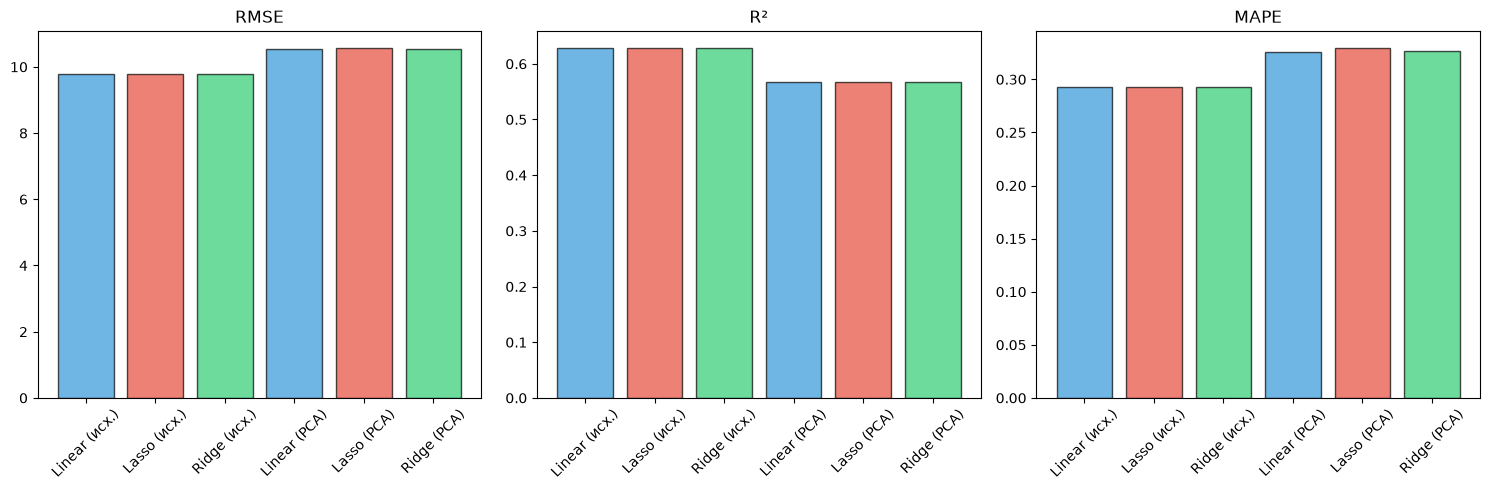

In [13]:
comparison = pd.DataFrame({
    'Модель': ['Linear (исх.)', 'Lasso (исх.)', 'Ridge (исх.)',
               'Linear (PCA)', 'Lasso (PCA)', 'Ridge (PCA)'],
    'RMSE': [rmse_lr, rmse_lasso, rmse_ridge, rmse_lr_pca, rmse_lasso_pca, rmse_ridge_pca],
    'R²':   [r2_lr, r2_lasso, r2_ridge, r2_lr_pca, r2_lasso_pca, r2_ridge_pca],
    'MAPE': [mape_lr, mape_lasso, mape_ridge, mape_lr_pca, mape_lasso_pca, mape_ridge_pca]
})
print(comparison.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, metric in enumerate(['RMSE', 'R²', 'MAPE']):
    axes[i].bar(comparison['Модель'], comparison[metric],
                color=['#3498db', '#e74c3c', '#2ecc71', '#3498db', '#e74c3c', '#2ecc71'],
                alpha=0.7, edgecolor='black')
    axes[i].set_title(metric)
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Пояснение.** Сравнительная таблица и графики: после PCA метрики почти не изменились (RMSE в пределах 0.1–0.3 МПа; R² ≈ 0.62–0.63; MAPE ≈ 0.30). Размерность снижена с 8 до 6 признаков, мультиколлинеарность устранена.

## Заключение

1. Загружен и проанализирован датасет Concrete Compressive Strength (1030×9). Пропусков и категориальных признаков нет.
2. Построена матрица корреляций; VIF > 5 для всех признаков подтверждает мультиколлинеарность.
3. Построены модели Linear, Lasso, Ridge; метрики: RMSE ≈ 10.5 МПа, R² ≈ 0.63, MAPE ≈ 0.30.
4. По графику остатков выявлена гетероскедастичность.
5. Применён PCA (6 компонент, ~95% дисперсии) после стандартизации.
6. На главных компонентах метрики сопоставимы с исходными — PCA устранил мультиколлинеарность без потери качества.

**Основной вывод:** PCA эффективен для устранения мультиколлинеарности. Линейные модели дают умеренное качество (R² ≈ 0.63) из-за нелинейной зависимости прочности от состава смеси. Для повышения точности можно использовать нелинейные модели (полиномиальная регрессия, случайный лес, градиентный бустинг).

## Список источников

1. Yeh, I-C. Modeling of strength of high-performance concrete using artificial neural networks // *Cement and Concrete Research*, 28(12), 1797–1808, 1998.
2. Kaggle: https://www.kaggle.com/datasets/sinamhd9/concrete-comprehensive-strength
3. UCI ML Repository: https://archive.ics.uci.edu/ml/datasets/Concrete+Compressive+Strength
4. Scikit-learn: https://scikit-learn.org/
5. Statsmodels: https://www.statsmodels.org/